# ExpTM: 11 × 11 control-grid run

**Purpose: generate a denser density heatmap as a preliminary Figure 2(b)-style attempt.**

This notebook uses the existing public checkpoint without retraining. It evaluates 11 T controls × 11 p controls, with 16 samples per point: **1,936 samples in total**. Every grid point is sampled directly; interpolation is not used to fill additional cells.

T control = 2…10 (step 0.8); p control = −1…1 (step 0.2); 100 diffusion steps; eta = gamma = 1; CPU.

The mapping to physical temperature and chemical potential, and the checkpoint's correspondence to the paper's Figure 2 run, remain unverified. The axes therefore use code controls. This notebook does not generate an MC reference or an error map.

**Instructions:** Extract all files into the same folder and open this notebook using your working ExpTM Python kernel. Edit PROJECT_ROOT below, then run the cells in order. Expect approximately one hour on CPU, depending on your machine. The runner checks a fixed 90-minute cumulative successful-cell sampling budget between grid points and stops when the budget is reached; it does not automatically extend the budget.

The original author source, checkpoint and input data are reused from your existing project and are not included in this code package.


In [1]:
from pathlib import Path
from datetime import datetime
import subprocess, sys

# Set this to the project directory containing the author_source folder.
PROJECT_ROOT = Path(r'C:\Users\user\Documents\GitHub\exptm_author_code_reproduction_v1')
# Alternative Windows example: Path(r'C:\Users\user\Documents\GitHub\active-matter-reproductions\exptm')
# Mac example: Path.home() / 'Documents/GitHub/active-matter-reproductions/exptm'
CODE_DIR = Path.cwd()

# Keep None for a new run; to resume, use the previously printed OUTPUT path.
RESUME_OUTPUT = None  # Path(r'...previous output directory...')
OUTPUT = (Path(RESUME_OUTPUT).expanduser().resolve() if RESUME_OUTPUT is not None
          else PROJECT_ROOT / 'outputs' / ('figure2_11x11_' + datetime.now().strftime('%Y%m%d_%H%M%S_%f')))
required = [
    PROJECT_ROOT / 'author_source/GC_Lattice_gas/data/LowMuT7.npy',
    PROJECT_ROOT / 'author_source/GC_Lattice_gas/data/HighMuT7.npy',
    PROJECT_ROOT / 'author_source/GC_Lattice_gas/expTM_data_genenration/thermomaps-root/models/model_1.pt',
    CODE_DIR / 'run_heatmap.py', CODE_DIR / 'plot_heatmap.py',
]
for path in required:
    assert path.is_file(), f'Missing file: {path}'
print('Python:', sys.executable)
print('OUTPUT:', OUTPUT)
print('Resume:', RESUME_OUTPUT is not None)


Python: c:\Users\user\AppData\Local\Python\pythoncore-3.14-64\python.exe
OUTPUT: C:\Users\user\Documents\GitHub\exptm_author_code_reproduction_v1\outputs\figure2_11x11_20261105_191642_105291
Resume: False


## Run sampling

This cell displays progress and writes a log beside the output directory. Use the notebook's Interrupt command to stop; completed grid points remain saved.

To resume, set RESUME_OUTPUT above to the original output directory, then rerun the setup cell and this cell. Resume requires the same recorded environment, paths, code, source, data and checkpoint. Start a new run when switching machines. Existing raw samples are checked before resuming, and only missing grid points are sampled. The same sampling seed is reset at each point.


In [ ]:
command = [sys.executable, '-u', str(CODE_DIR / 'run_heatmap_extension.py'),
           '--root', str(PROJECT_ROOT), '--output', str(OUTPUT)]
if RESUME_OUTPUT is not None:
    command.append('--resume')
# Keep the log beside the output directory; the runner must create the new directory itself.
OUTPUT.parent.mkdir(parents=True, exist_ok=True)
log_path = OUTPUT.parent / (OUTPUT.name + '.log')
with log_path.open('a', encoding='utf-8') as log:
    process = subprocess.Popen(command, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                               text=True, encoding='utf-8', errors='replace', bufsize=1)
    try:
        for line in process.stdout:
            print(line, end='')
            log.write(line)
            log.flush()
        returncode = process.wait()
    except KeyboardInterrupt:
        process.terminate()
        try:
            process.wait(timeout=5)
        except subprocess.TimeoutExpired:
            process.kill()
            process.wait()
        print('Stopped; completed cells are saved. Resume output:', OUTPUT)
        raise
    finally:
        process.stdout.close()
if returncode:
    raise RuntimeError(f'Sampling stopped with code {returncode}; inspect {log_path}')
print('Sampling completed:', OUTPUT)


Traceback (most recent call last):
  File "c:\Users\user\Documents\GitHub\active-matter-reproductions\exptm\author_source\run_heatmap.py", line 143, in <module>
    main()
    ~~~~^^
  File "c:\Users\user\Documents\GitHub\active-matter-reproductions\exptm\author_source\run_heatmap.py", line 75, in main
    out.mkdir(parents=True, exist_ok=False)
    ~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\user\AppData\Local\Python\pythoncore-3.14-64\Lib\pathlib\__init__.py", line 1011, in mkdir
    os.mkdir(self, mode)
    ~~~~~~~~^^^^^^^^^^^^
FileExistsError: [WinError 183] 当文件已存在时，无法创建该文件。: 'C:\\Users\\user\\Documents\\GitHub\\exptm_author_code_reproduction_v1\\outputs\\figure2_extension_20261105_201328_654786'


RuntimeError: Sampling stopped with code 1; inspect C:\Users\user\Documents\GitHub\exptm_author_code_reproduction_v1\outputs\figure2_extension_20261105_201328_654786.log

## Plot saved results

This cell reads statistics from the saved samples. The colorbar is fixed at 0–1. Values are plotted without adjustment to match the paper.


{'status': 'CONTROL_GRID_COMPLETED', 'samples': 192, 'sampling_wall_seconds': 193.71816600015154, 'current_session_wall_seconds': 193.76020230003633, 'physical_reproduction_validated': False}


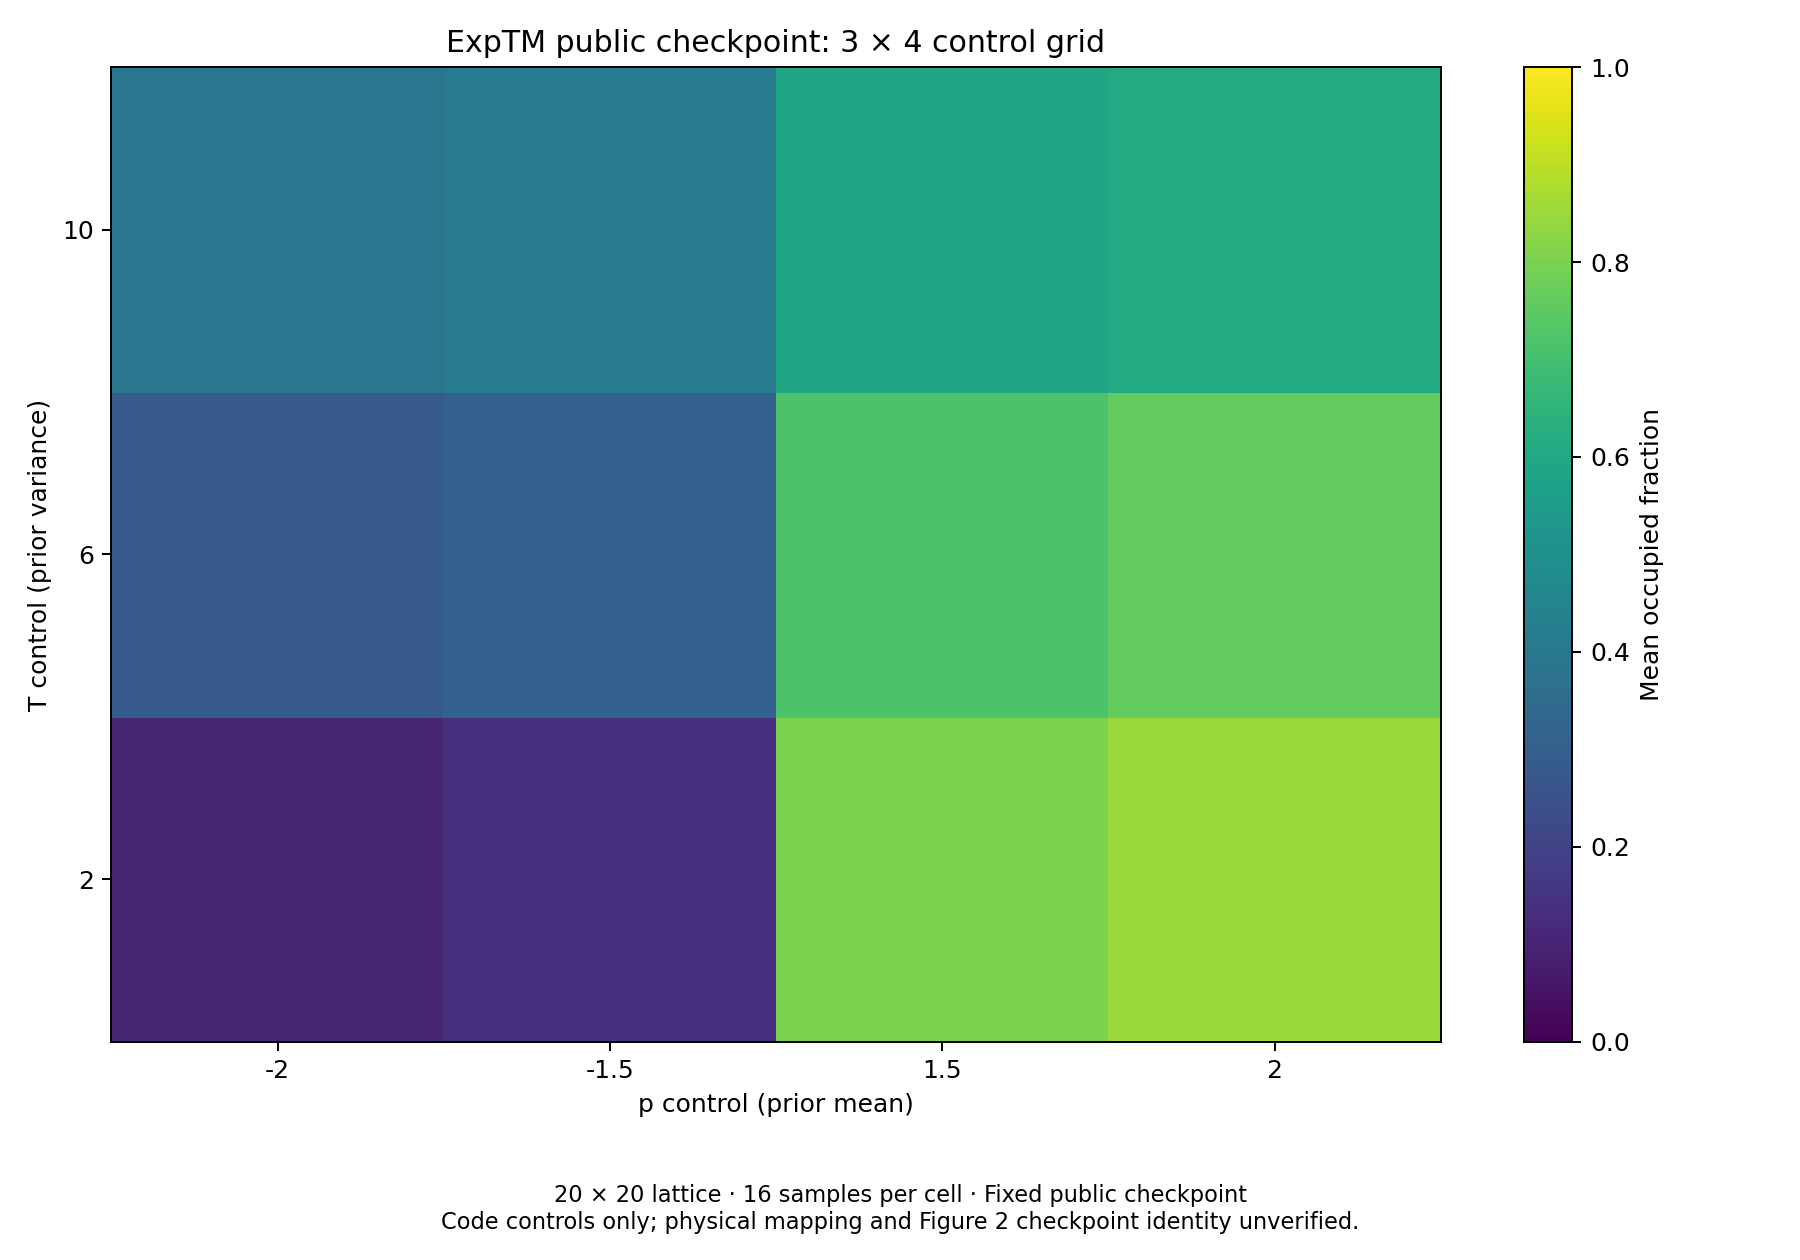

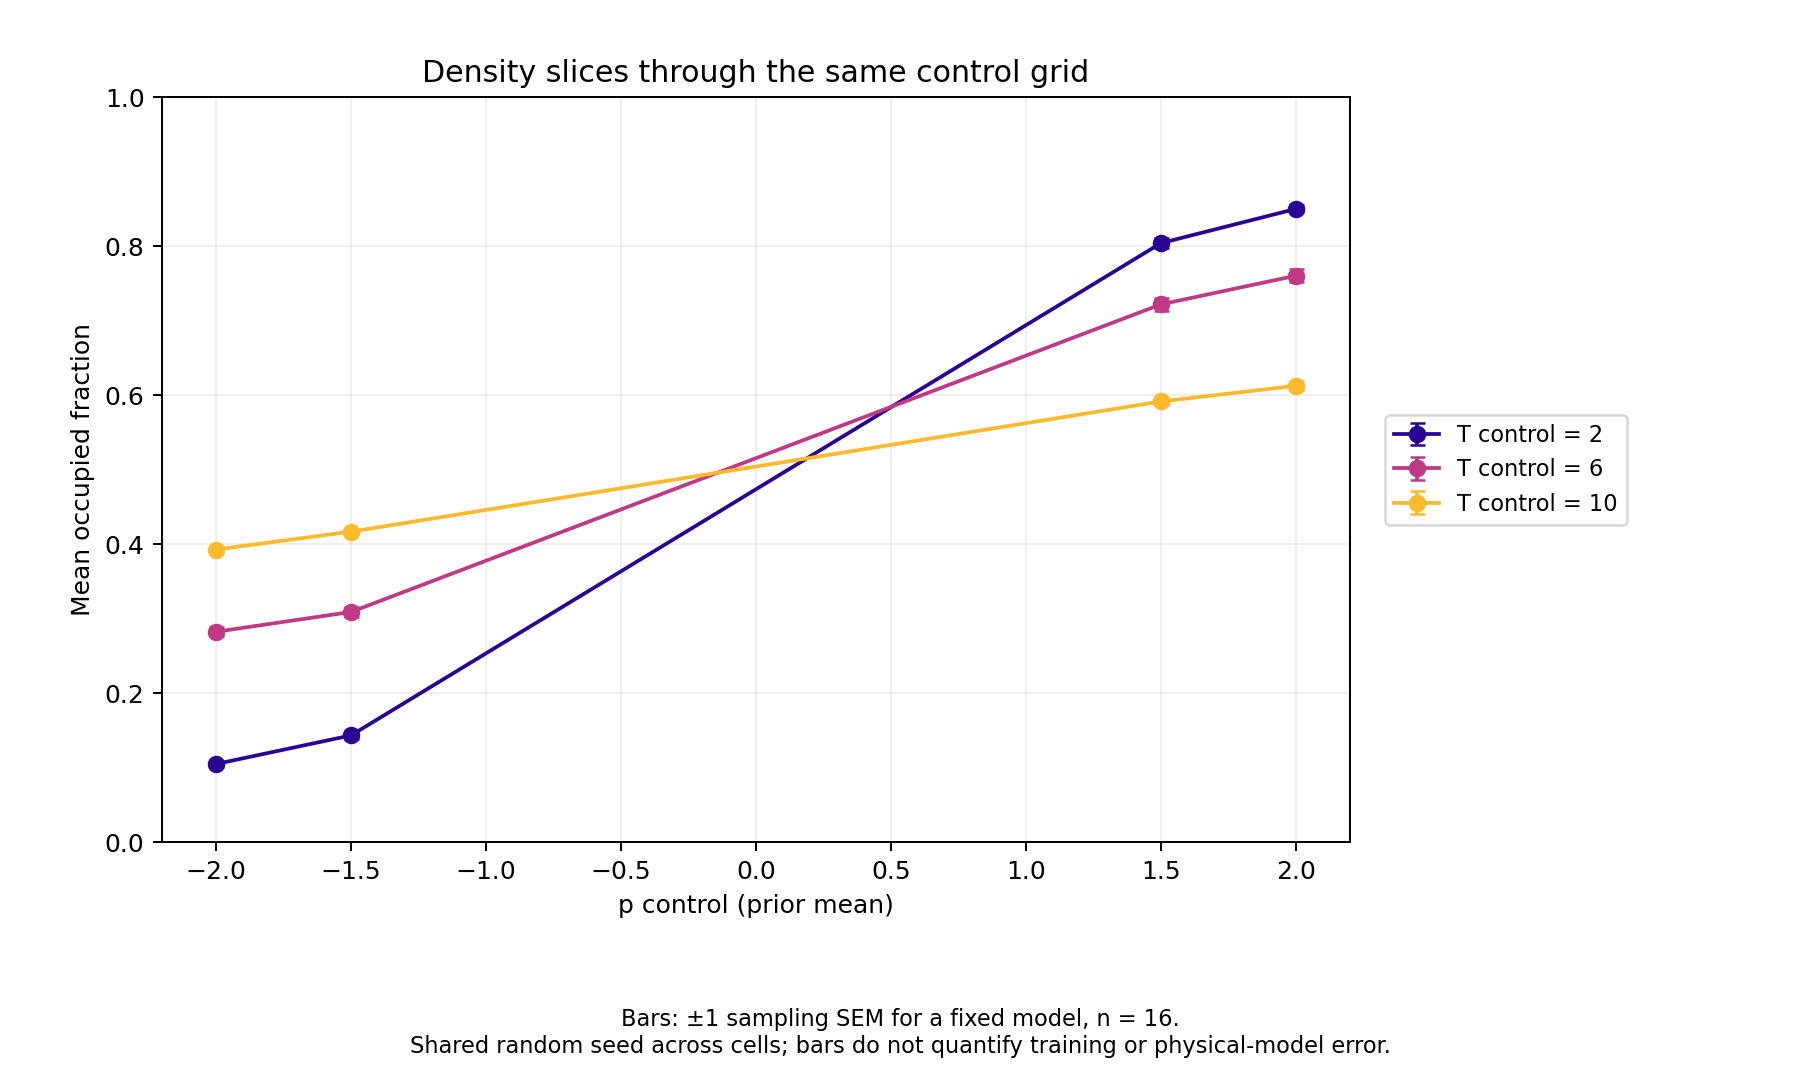

In [9]:
subprocess.run([sys.executable, str(CODE_DIR / 'plot_heatmap.py'), str(OUTPUT)], check=True)
import json
from IPython.display import Image, display
print(json.loads((OUTPUT / 'completion.json').read_text()))
display(Image(filename=str(OUTPUT / 'density_heatmap.png')))
display(Image(filename=str(OUTPUT / 'density_slices.png')))


## Export

The archive contains raw samples, per-sample densities, means, sampling SEMs, configuration, hashes, CSV data and figures. Sampling SEM does not quantify training variability or physical accuracy.


In [4]:
import shutil
shutil.copy2(log_path, OUTPUT / 'run.log')
archive = shutil.make_archive(str(OUTPUT), 'zip', root_dir=OUTPUT.parent, base_dir=OUTPUT.name)
print('Results ZIP:', archive)


Results ZIP: C:\Users\user\Documents\GitHub\exptm_author_code_reproduction_v1\outputs\figure2_11x11_20261105_191642_105291.zip


Baseline: C:\Users\user\Documents\GitHub\exptm_author_code_reproduction_v1\outputs\figure2_11x11_20261105_191642_105291
Extension: C:\Users\user\Documents\GitHub\exptm_author_code_reproduction_v1\outputs\figure2_extension_20261105_201328_654786


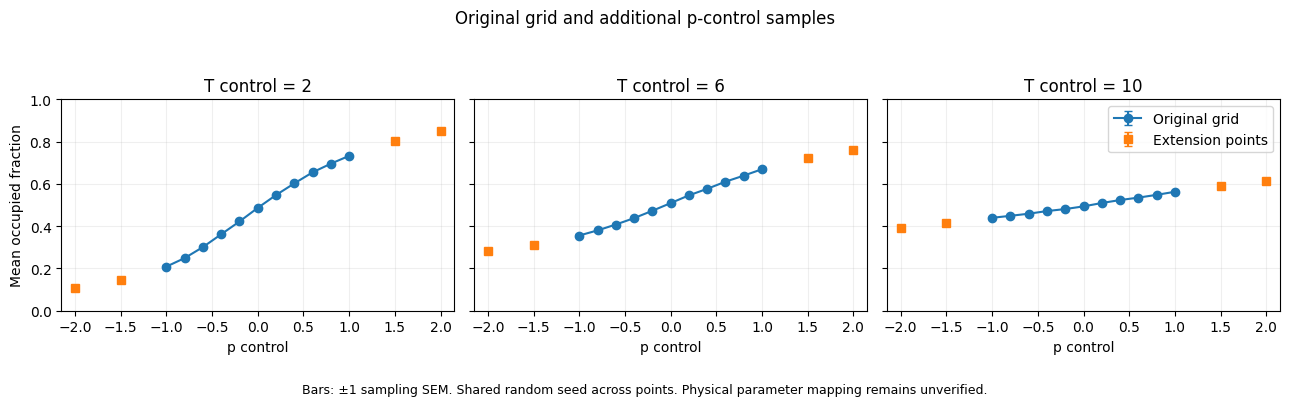

Saved: C:\Users\user\Documents\GitHub\exptm_author_code_reproduction_v1\outputs\figure2_extension_20261105_201328_654786\density_extension_comparison.png


In [11]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt

EXT_OUTPUT = Path(OUTPUT)
ext_config = json.loads((EXT_OUTPUT / "config.json").read_text())

with np.load(EXT_OUTPUT / "heatmap.npz") as data:
    ext = {key: data[key].copy() for key in ["T", "p", "mean", "sem"]}

assert ext["mean"].shape == (3, 4), "OUTPUT must point to the completed extension."

# Find a compatible completed 11x11 baseline.
match_keys = [
    "checkpoint_sha256", "data_sha256", "source_sha256",
    "samples_per_cell", "batch_size", "sampling_seed_reset_each_cell",
    "setup_seed", "diffusion_steps", "eta", "gamma",
    "decoder", "backbone_eval_mode", "device", "python", "torch", "numpy",
]

candidates = []
for grid_file in (PROJECT_ROOT / "outputs").glob("*/heatmap.npz"):
    folder = grid_file.parent
    if not (folder / "completion.json").is_file():
        continue
    config = json.loads((folder / "config.json").read_text())
    if not all(
        key in config and key in ext_config
        and config[key] == ext_config[key]
        for key in match_keys
    ):
        continue
    with np.load(grid_file) as data:
        if data["mean"].shape == (11, 11):
            candidates.append(grid_file)

assert candidates, "No compatible completed 11x11 baseline found."

baseline_file = max(candidates, key=lambda path: path.stat().st_mtime)
print("Baseline:", baseline_file.parent)
print("Extension:", EXT_OUTPUT)

with np.load(baseline_file) as data:
    base = {key: data[key].copy() for key in ["T", "p", "mean", "sem"]}

fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)

for i, (ax, temperature) in enumerate(zip(axes, ext["T"])):
    matches = np.flatnonzero(np.isclose(base["T"], temperature))
    assert len(matches) == 1, "Temperature missing from baseline."
    j = matches[0]

    ax.errorbar(
        base["p"], base["mean"][j], yerr=base["sem"][j],
        fmt="o-", capsize=3, label="Original grid",
    )
    ax.errorbar(
        ext["p"], ext["mean"][i], yerr=ext["sem"][i],
        fmt="s", linestyle="none", capsize=3,
        label="Extension points",
    )
    ax.set(
        title=f"T control = {temperature:g}",
        xlabel="p control",
        xlim=(-2.15, 2.15),
        ylim=(0, 1),
    )
    ax.grid(alpha=0.2)

axes[0].set_ylabel("Mean occupied fraction")
axes[-1].legend()
fig.suptitle("Original grid and additional p-control samples")
fig.tight_layout(rect=(0, 0.08, 1, 0.93))
fig.text(
    0.5, 0.02,
    "Bars: ±1 sampling SEM. Shared random seed across points. "
    "Physical parameter mapping remains unverified.",
    ha="center", fontsize=9,
)

figure_path = EXT_OUTPUT / "density_extension_comparison.png"
fig.savefig(figure_path, dpi=200, bbox_inches="tight")
plt.show()
print("Saved:", figure_path)

Original 11x11 figure: C:\Users\user\Documents\GitHub\exptm_author_code_reproduction_v1\outputs\figure2_11x11_20261105_191642_105291\density_heatmap.png


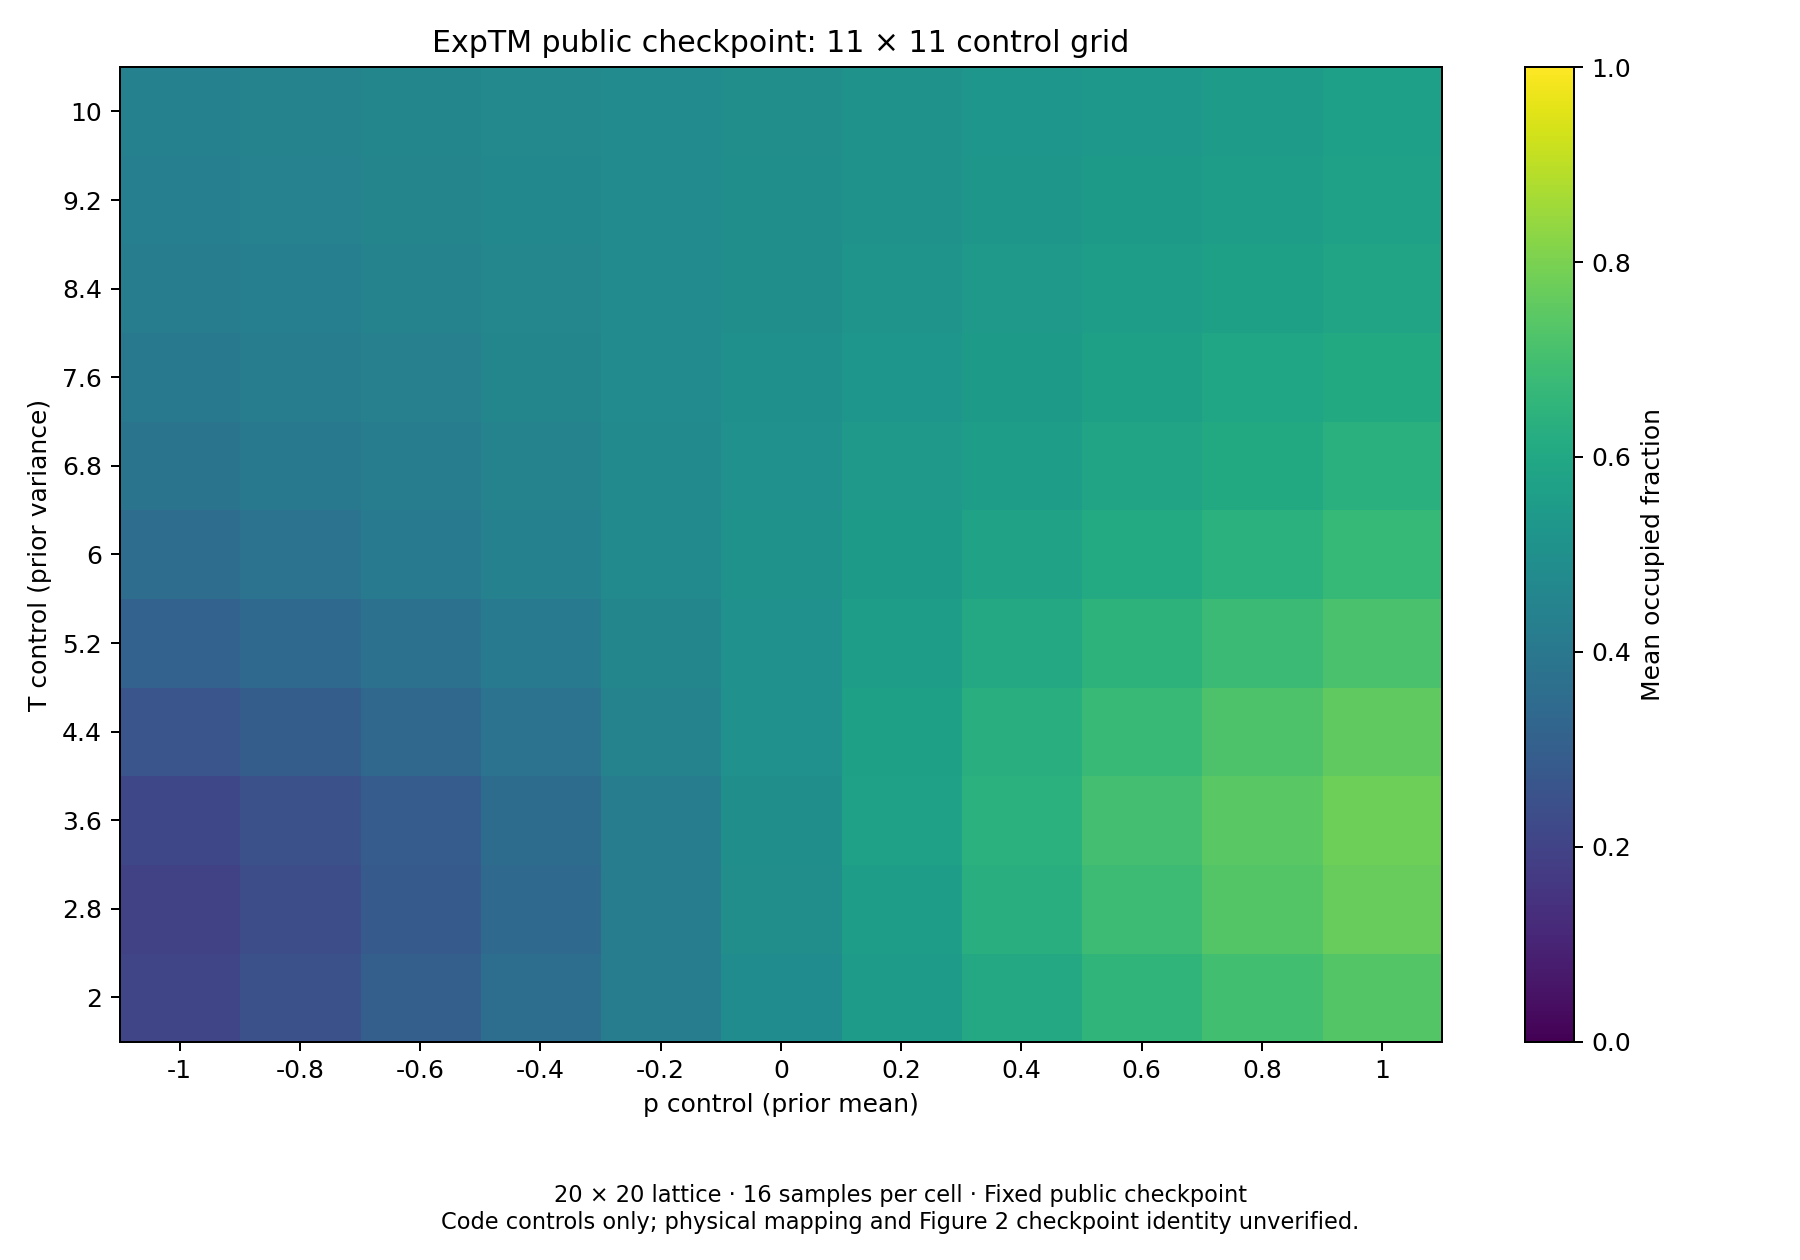

In [12]:
from pathlib import Path
import numpy as np
from IPython.display import Image, display

output_root = PROJECT_ROOT / "outputs"
found = False

for grid_file in sorted(output_root.glob("*/heatmap.npz")):
    with np.load(grid_file) as data:
        if data["mean"].shape != (11, 11):
            continue

    image_path = grid_file.parent / "density_heatmap.png"
    if image_path.exists():
        found = True
        print("Original 11x11 figure:", image_path)
        display(Image(filename=str(image_path)))

if not found:
    print("No saved 11x11 figure found in:", output_root)